In [2]:
import numpy as np
import matplotlib.pyplot as plt
import scipy as scp

In [2]:
data = np.loadtxt("out.txt",delimiter=" ")
data /= 10

In [3]:
cx = scp.signal.correlate(data[:,0],data[:,0],mode="same")/data.shape[0]
cy = scp.signal.correlate(data[:,1],data[:,1],mode="same")/data.shape[0]
cz = scp.signal.correlate(data[:,2],data[:,2],mode="same")/data.shape[0]

In [4]:
c=cx+cy+cz

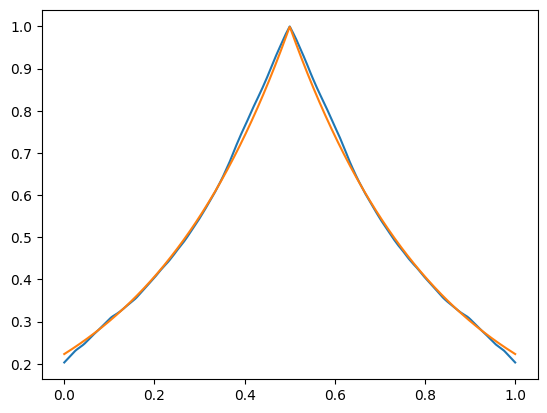

In [6]:
x=np.linspace(0,1,1000)
plt.plot(1e-6*np.arange(len(c)),c)
plt.plot(x,np.exp(-3*np.abs(x-0.5)))

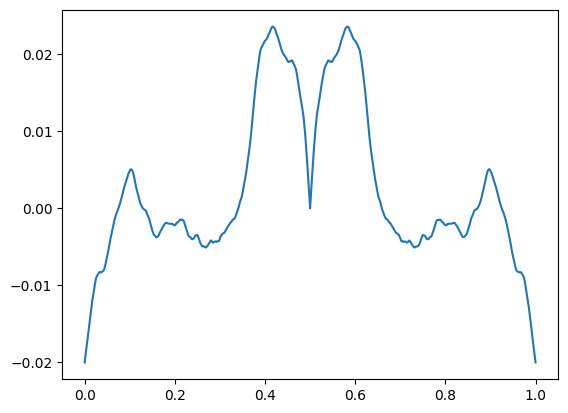

In [15]:
y = 1e-6*np.arange(len(c))
plt.plot(y,c-np.exp(-3*np.abs(y-0.5)))

# TODO
* korelacje dla harmonik sferycznych, izotropowa dyfuzja, m i E w kierunku ez
* l=1 m=0,
* \muE/kT ~= 1/100
* korelacje dla funkcji wignera
* jeden przykład anizotropowy

# Funkcje Wignera od kwaternionu

In [ ]:
def compiled_wigner_d_from_quaternion(l, m, n, q):
    """
    Computes a specific Wigner D-matrix element for given l, m, n from a quaternion.
    q: numpy array of shape (4,) representing [q0, q1, q2, q3]
    """
    s2 = 1.4142135623730951 # sqrt(2)
    s6 = 2.449489742783178  # sqrt(6)
    
    # Map Mathematica's 1-indexed array access to 0-indexed Python arrays
    a = q[:,0] + 1j * q[:,3]
    b = q[:,2] + 1j * q[:,1]
    
    ap = np.conj(a)
    bp = np.conj(b)
    
    res = 0.0 + 0.0j
    
    # l = 0
    if l == 0 and m == 0 and n == 0:
        res = 1.0 + 0.0j
        
    # l = 1
    elif l == 1:
        if m == -1:
            if n == -1: res = ap * ap
            elif n == 0: res = s2 * ap * b
            elif n == 1: res = b * b
        elif m == 0:
            if n == -1: res = -s2 * ap * bp
            elif n == 0: res = a * ap - b * bp
            elif n == 1: res = s2 * a * b
        elif m == 1:
            if n == -1: res = bp * bp
            elif n == 0: res = -s2 * a * bp
            elif n == 1: res = a * a
            
    # l = 2
    elif l == 2:
        if m == -2:
            if n == -2: res = ap**4
            elif n == -1: res = 2.0 * b * ap**3
            elif n == 0: res = s6 * ap**2 * b**2
            elif n == 1: res = 2.0 * ap * b**3
            elif n == 2: res = b**4
        elif m == -1:
            if n == -2: res = -2.0 * ap**3 * bp
            elif n == -1: res = ap**3 * a - 3.0 * ap**2 * b * bp
            elif n == 0: res = s6 * ap**2 * a * b - s6 * ap * b**2 * bp
            elif n == 1: res = 3.0 * a * ap * b**2 - b**3 * bp
            elif n == 2: res = 2.0 * a * b**3
        elif m == 0:
            if n == -2: res = s6 * ap**2 * bp**2
            elif n == -1: res = -s6 * ap**2 * a * bp + s6 * ap * b * bp**2
            elif n == 0: res = a**2 * ap**2 - 4.0 * a * ap * b * bp + b**2 * bp**2
            elif n == 1: res = s6 * ap * a**2 * b - s6 * a * b**2 * bp
            elif n == 2: res = s6 * a**2 * b**2
        elif m == 1:
            if n == -2: res = -2.0 * ap * bp**3
            elif n == -1: res = 3.0 * a * ap * bp**2 - b * bp**3
            elif n == 0: res = -s6 * ap * a**2 * bp + s6 * a * b * bp**2
            elif n == 1: res = ap * a**3 - 3.0 * a**2 * b * bp
            elif n == 2: res = 2.0 * a**3 * b
        elif m == 2:
            if n == -2: res = bp**4
            elif n == -1: res = -2.0 * a * bp**3
            elif n == 0: res = s6 * a**2 * bp**2
            elif n == 1: res = -2.0 * a**3 * bp
            elif n == 2: res = a**4

    return res

In [14]:
q=np.array([[1,1,1,0],[1,1,1,0]])
compiled_wigner_d_from_quaternion(1,0,0,q)

array([-1.+0.j, -1.+0.j])

In [36]:
q=np.loadtxt("quat.txt")

In [37]:
wigner = compiled_wigner_d_from_quaternion(1,0,0,q)

In [23]:
cor = scp.signal.correlate(wigner,np.conj(wigner),mode="same")

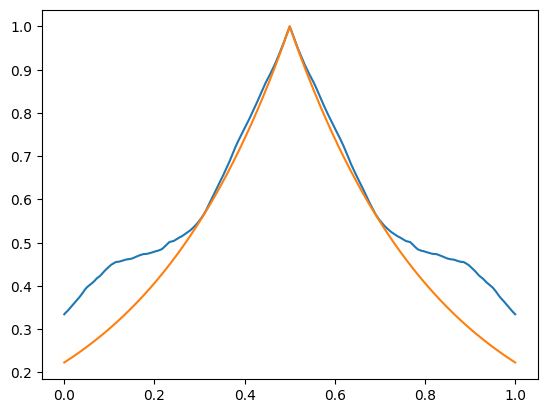

In [35]:
x = 1e-6*np.arange(1e6+1)
plt.plot(x,cor/np.max(cor))
plt.plot(x,np.exp(-3*np.abs(x-0.5)))